# Análisis características EPL
En este documento analizaremos las relaciones existentes de las variables de los partidos en la premier league

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

epl= pd.read_csv('/Users/saulmartinezs/Documents/VS/epl_env/Dataset/epl_final.csv')

print('Cantidad de datos')
print(epl.shape)


columnas = epl.columns.tolist()
types = epl.dtypes
conteo_columnas = epl.count()

print(columnas)
print(types,conteo_columnas)






Cantidad de datos
(9380, 22)
['Season', 'MatchDate', 'HomeTeam', 'AwayTeam', 'FullTimeHomeGoals', 'FullTimeAwayGoals', 'FullTimeResult', 'HalfTimeHomeGoals', 'HalfTimeAwayGoals', 'HalfTimeResult', 'HomeShots', 'AwayShots', 'HomeShotsOnTarget', 'AwayShotsOnTarget', 'HomeCorners', 'AwayCorners', 'HomeFouls', 'AwayFouls', 'HomeYellowCards', 'AwayYellowCards', 'HomeRedCards', 'AwayRedCards']
Season                 str
MatchDate              str
HomeTeam               str
AwayTeam               str
FullTimeHomeGoals    int64
FullTimeAwayGoals    int64
FullTimeResult         str
HalfTimeHomeGoals    int64
HalfTimeAwayGoals    int64
HalfTimeResult         str
HomeShots            int64
AwayShots            int64
HomeShotsOnTarget    int64
AwayShotsOnTarget    int64
HomeCorners          int64
AwayCorners          int64
HomeFouls            int64
AwayFouls            int64
HomeYellowCards      int64
AwayYellowCards      int64
HomeRedCards         int64
AwayRedCards         int64
dtype: object S

In [3]:
epl.head()

,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,...,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,2000-08-19,Charlton,Man City,4,0,H,2,0,H,...,14,4,6,6,13,12,1,2,0,0
1,2000/01,2000-08-19,Chelsea,West Ham,4,2,H,1,0,H,...,10,5,7,7,19,14,1,2,0,0
2,2000/01,2000-08-19,Coventry,Middlesbrough,1,3,A,1,1,D,...,3,9,8,4,15,21,5,3,1,0
3,2000/01,2000-08-19,Derby,Southampton,2,2,D,1,2,A,...,4,6,5,8,11,13,1,1,0,0
4,2000/01,2000-08-19,Leeds,Everton,2,0,H,2,0,H,...,8,6,6,4,21,20,1,3,0,0


In [4]:
epl.head()
epl.describe()

,FullTimeHomeGoals,FullTimeAwayGoals,HalfTimeHomeGoals,HalfTimeAwayGoals,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
count,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000
mean,1.535394,1.182623,0.688273,0.518763,13.617484,10.810661,5.973134,4.693710,6.040299,4.774733,11.276333,11.765672,1.468124,1.792431,0.062473,0.085288
std,1.305432,1.157414,0.835079,0.735357,5.356424,4.696501,3.267954,2.750045,3.110619,2.749541,3.750250,3.924179,1.217190,1.288481,0.253221,0.290183
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,10.000000,7.000000,4.000000,3.000000,4.000000,3.000000,9.000000,9.000000,1.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,13.000000,10.000000,6.000000,4.000000,6.000000,4.000000,11.000000,12.000000,1.000000,2.000000,0.000000,0.000000
75%,2.000000,2.000000,1.000000,1.000000,17.000000,14.000000,8.000000,6.000000,8.000000,6.000000,14.000000,14.000000,2.000000,3.000000,0.000000,0.000000
max,9.000000,9.000000,5.000000,5.000000,43.000000,37.000000,24.000000,20.000000,20.000000,19.000000,33.000000,29.000000,7.000000,9.000000,3.000000,2.000000


# Exploración de datos faltantes dataset

In [5]:
informe = pd.DataFrame({
    'faltantes': epl.isna().sum(),
    'porcentaje':epl.isna().sum()*100
})

informe

,faltantes,porcentaje
Season,0,0
MatchDate,0,0
HomeTeam,0,0
AwayTeam,0,0
FullTimeHomeGoals,0,0
FullTimeAwayGoals,0,0
FullTimeResult,0,0
HalfTimeHomeGoals,0,0
HalfTimeAwayGoals,0,0
HalfTimeResult,0,0


No hay ningun dato faltante en el dataset.

# Análisis de distribución

Se analizarán las variables de interés y su distribución

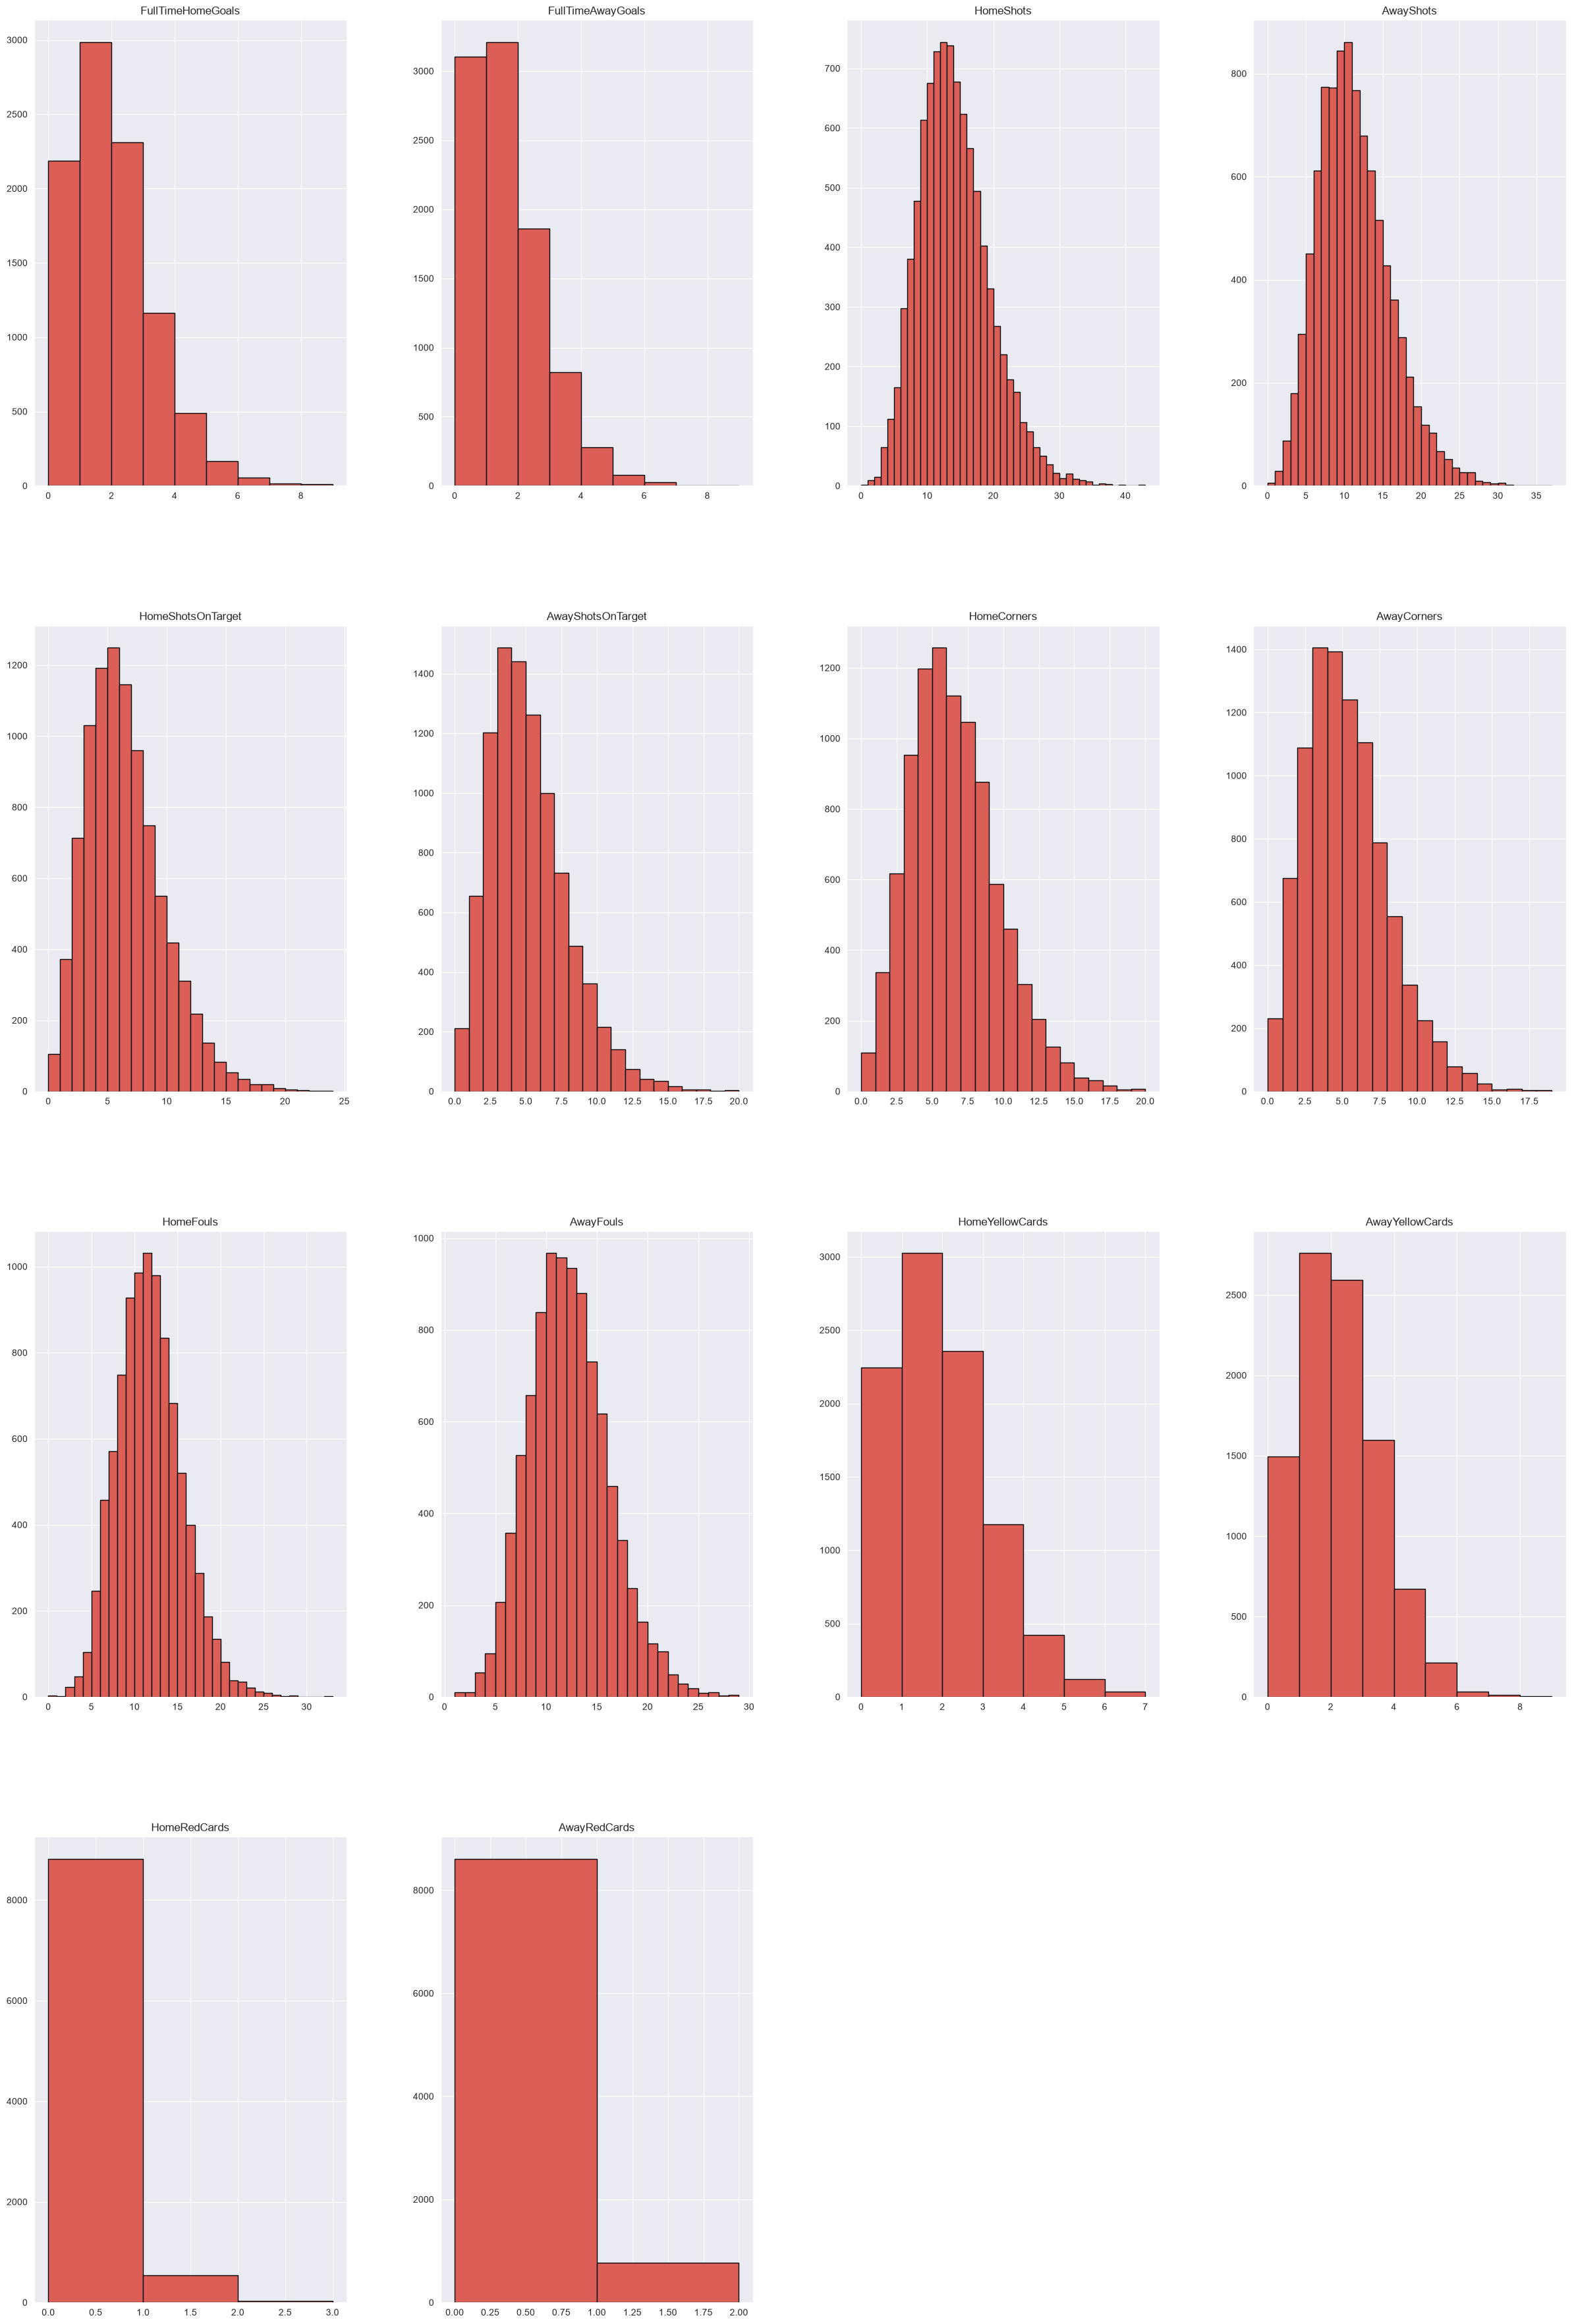

In [6]:
import seaborn as sns
sns.set_style('dark')
sns.set_palette('hls',8)

datos_columnas=epl[[
    'FullTimeHomeGoals',
    'FullTimeAwayGoals',
    'FullTimeResult',
    'HalfTimeResult',
    'HomeShots',
    'AwayShots',
    'HomeShotsOnTarget',
    'AwayShotsOnTarget',
    'HomeCorners',
    'AwayCorners',
    'HomeFouls',
    'AwayFouls',
    'HomeYellowCards',
    'AwayYellowCards',
    'HomeRedCards',
    'AwayRedCards'
    ]]

datos_columnas.hist(figsize=(30,45), bins='scott', edgecolor='black') #ancho alto

plt.show()


# Anális categoríco



In [ ]:
categoria=epl[epl['FullTimeResult'].isin(['H','D','A'])]

sns.countplot(data=categoria,x='FullTimeResult')

plt.show()

KeyError: ('FullTimeResult', 'HalfTimeResult')

Podemos observar que el factor de jugar como local influye en las victorias de los equipos, por lo que historicamente tenemos que tomar en cuenta esta variable.

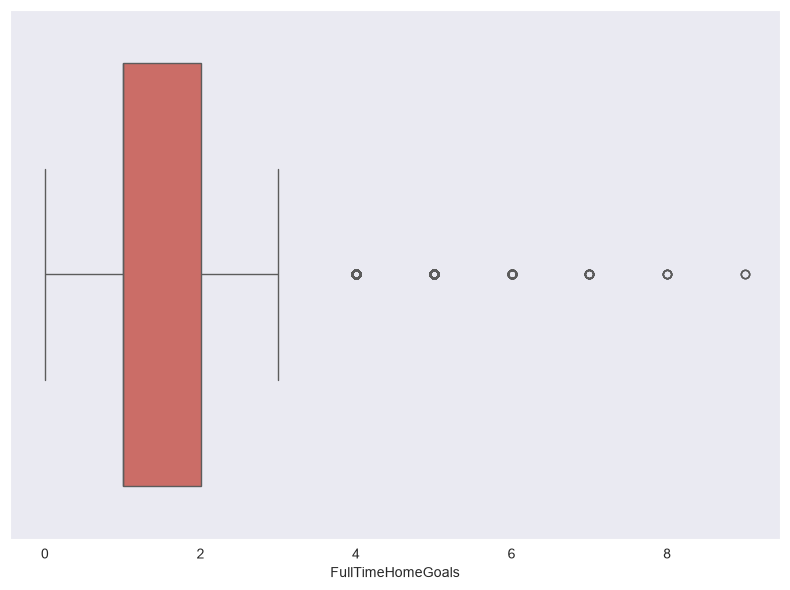

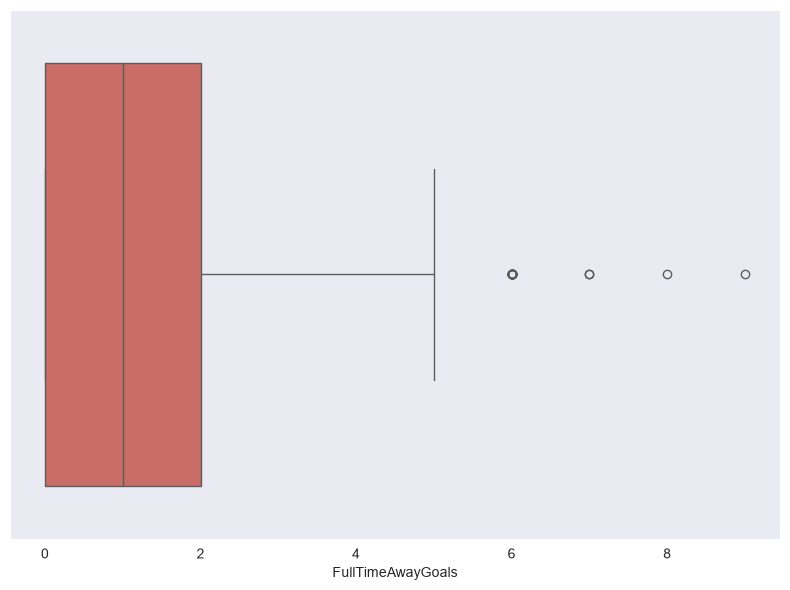

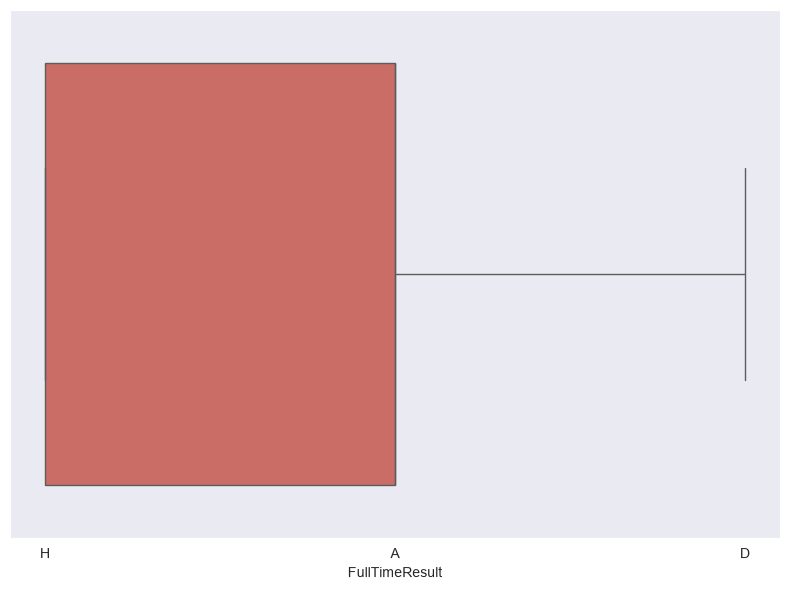

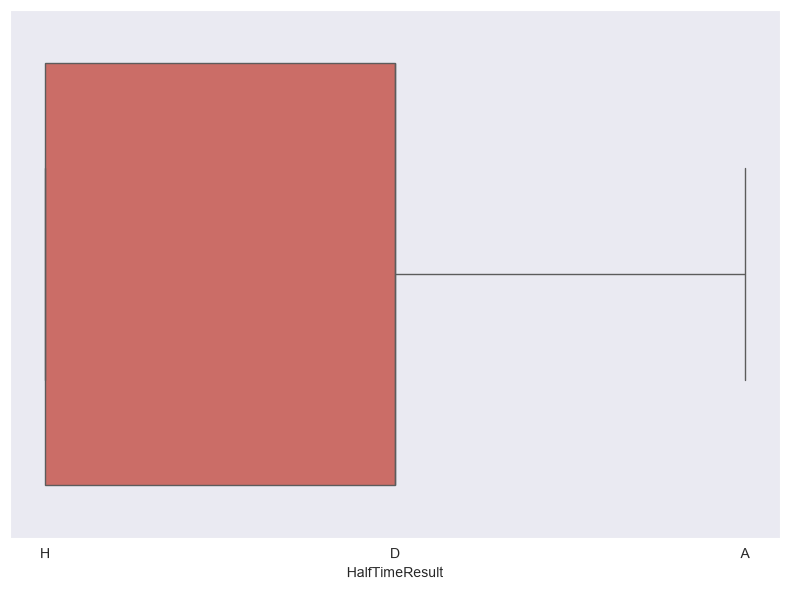

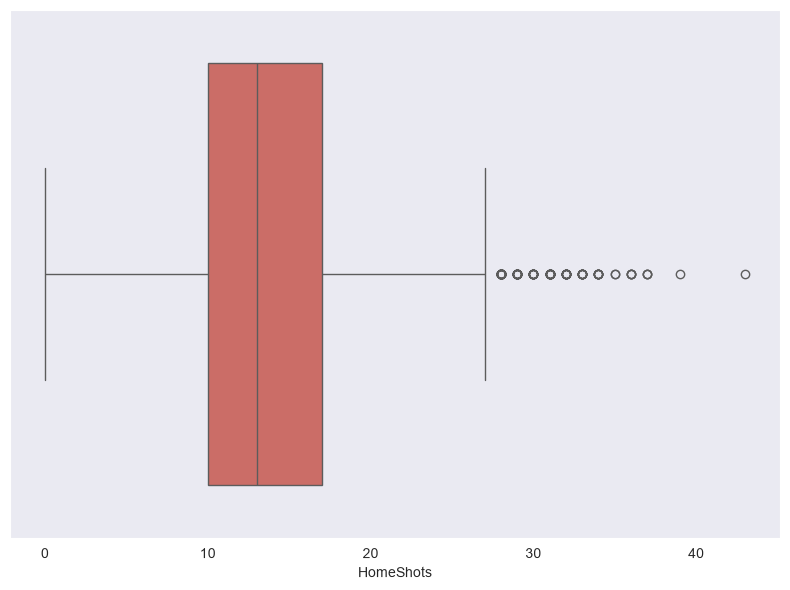

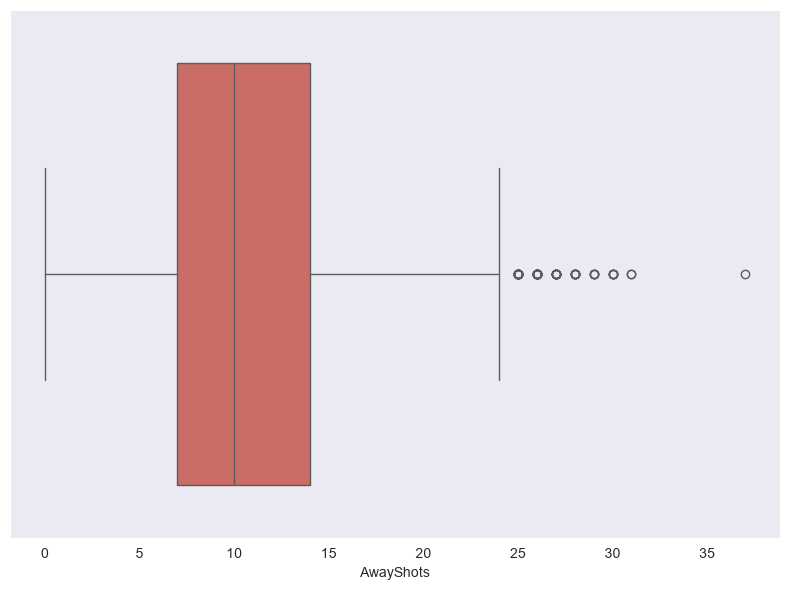

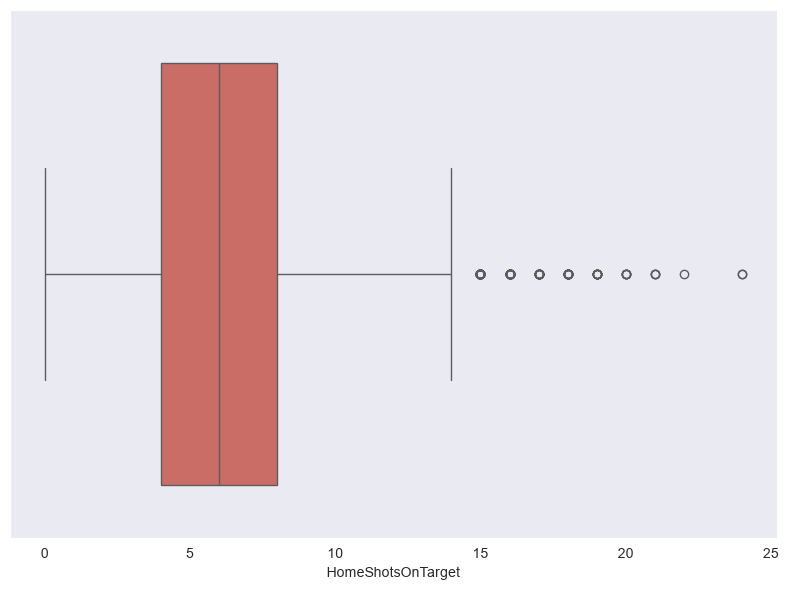

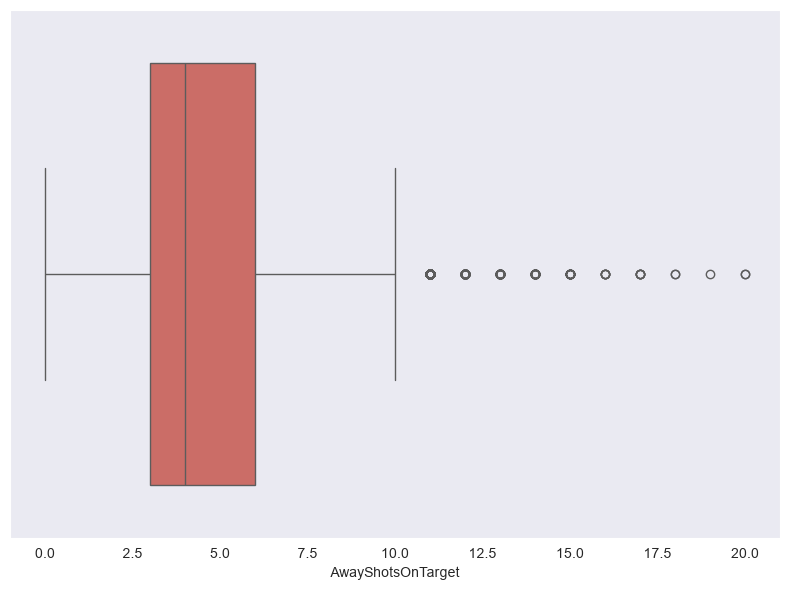

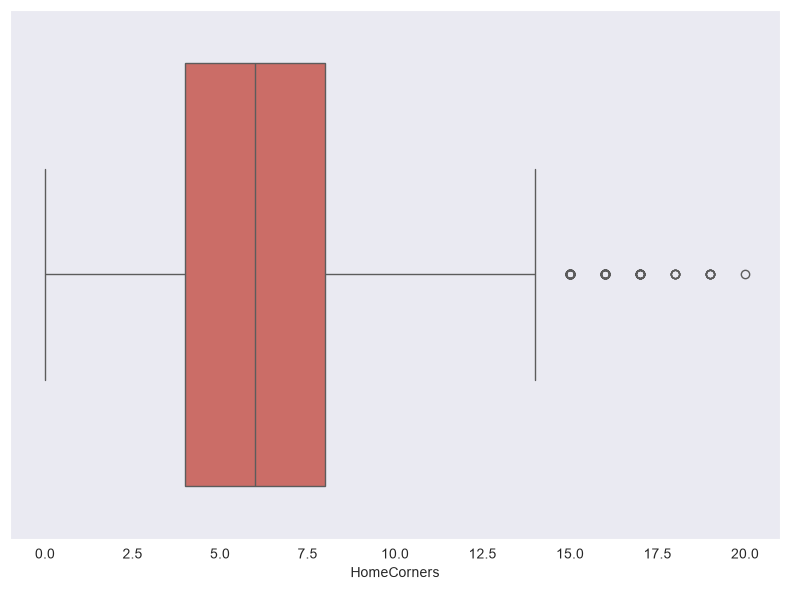

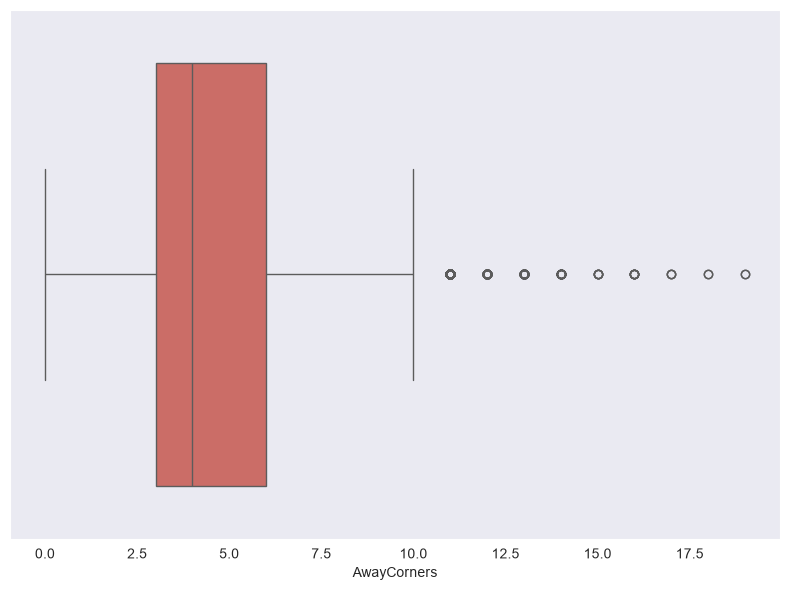

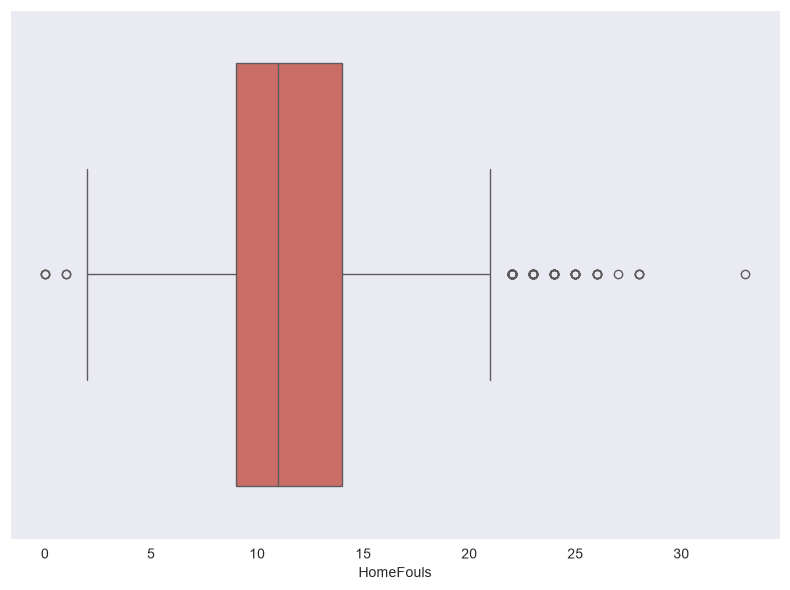

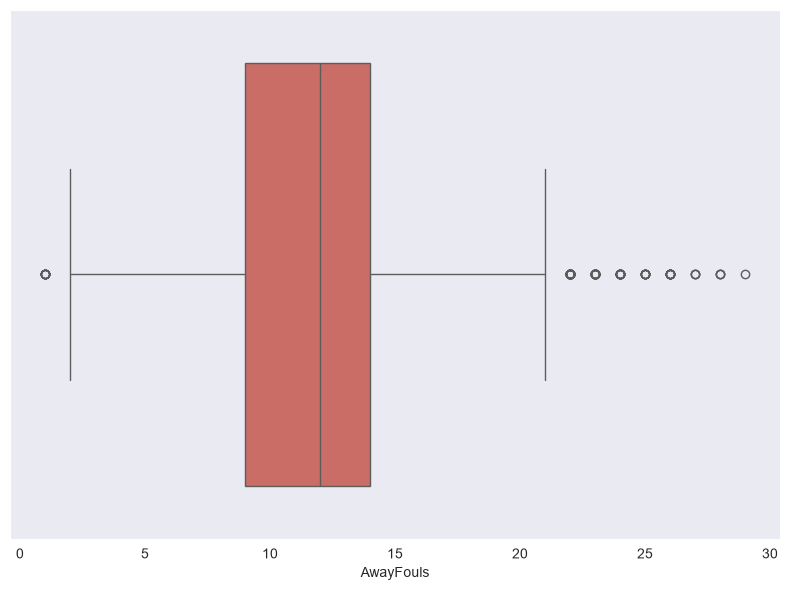

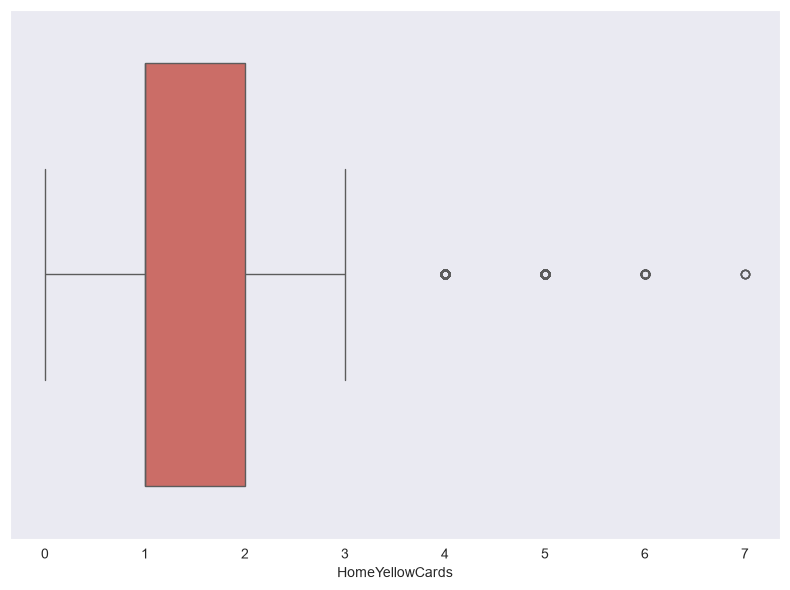

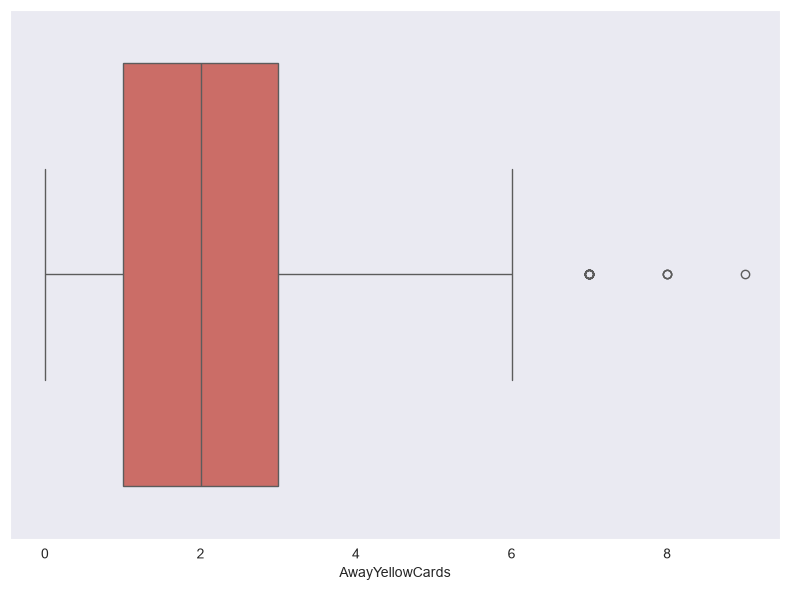

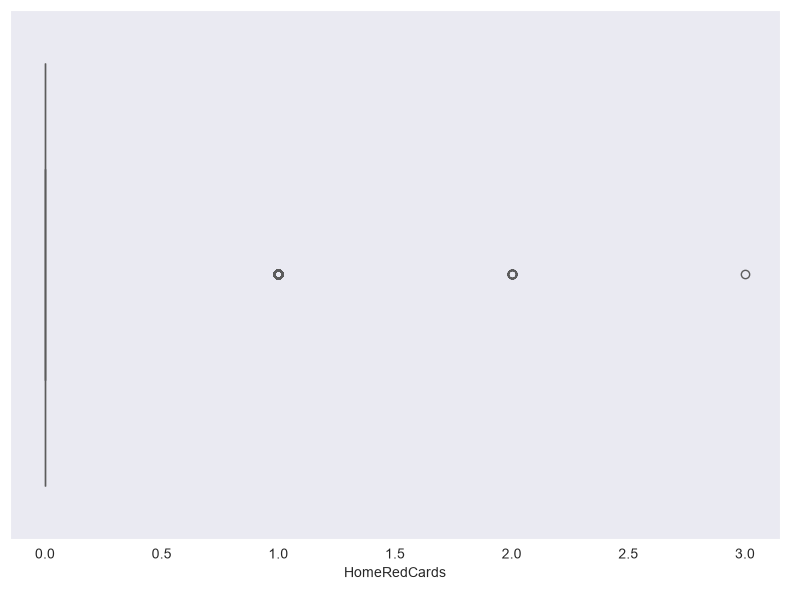

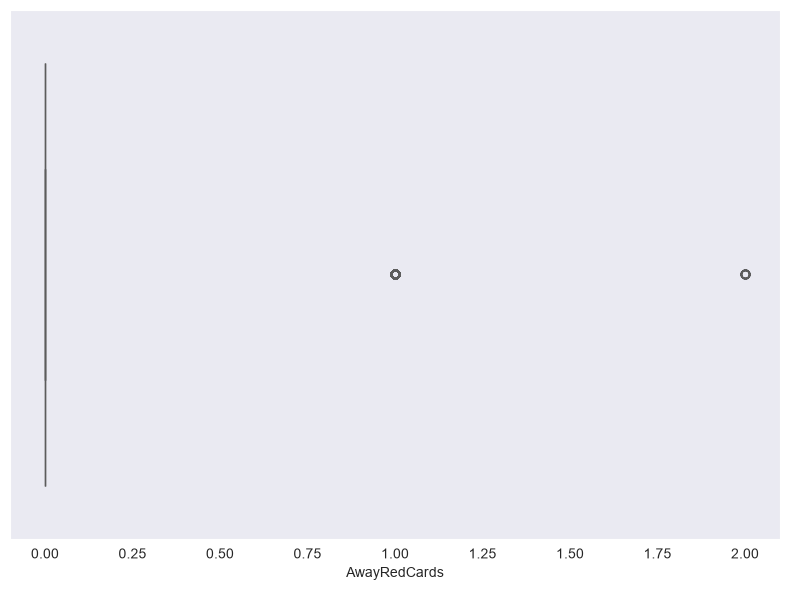

In [19]:
for variable in datos_columnas:
    plt.figure(figsize=(8,6))
    sns.boxplot(x=epl[variable])
    plt.tight_layout()
    plt.show()

# Matriz de correlación

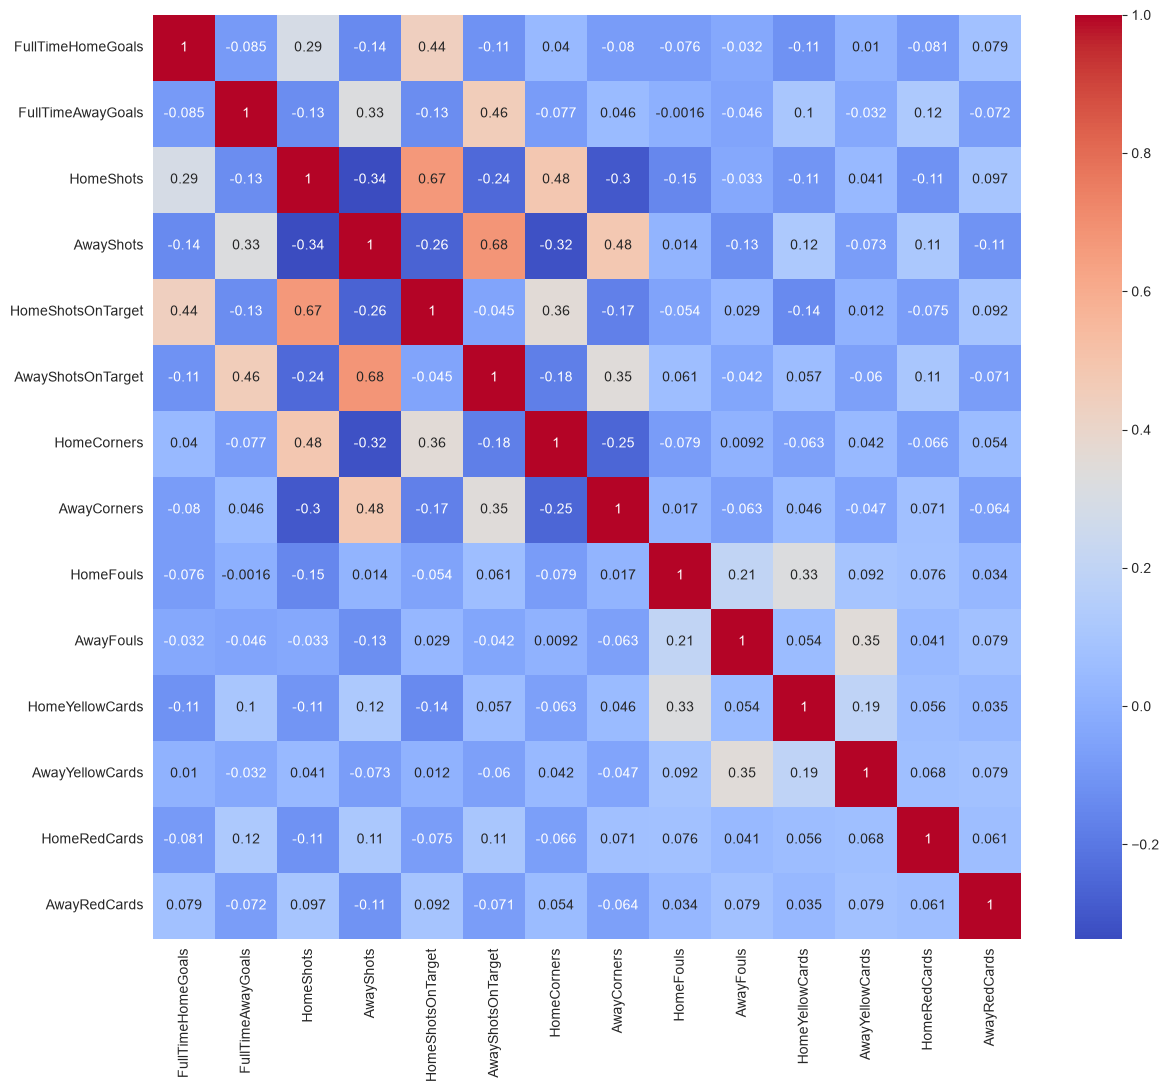

In [9]:
datos_columnas2=[
    'FullTimeHomeGoals',
    'FullTimeAwayGoals',
    'HomeShots',
    'AwayShots',
    'HomeShotsOnTarget',
    'AwayShotsOnTarget',
    'HomeCorners',
    'AwayCorners',
    'HomeFouls',
    'AwayFouls',
    'HomeYellowCards',
    'AwayYellowCards',
    'HomeRedCards',
    'AwayRedCards'
    ]

pearson = epl[datos_columnas2].corr(method='pearson')

plt.figure(figsize=(14,12))

sns.heatmap(pearson, annot=True, cmap='coolwarm')
plt.show()